In [1]:
import sys
sys.path.append("..")

import pandas as pd

from clean_data import feature_engineering
from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import shap
import numpy as np
import matplotlib.pyplot as plt


c:\Users\tprze\Desktop\ShelterPal\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df= pd.read_csv("../data/austin/raw/aac_intakes_outcomes.csv")

df = feature_engineering(df)
df_dogs = df[df["animal_type"] == "Dog"]
df_dogs = df_dogs.drop(columns=["young_and_cat","animal_type"])

df_dogs["day_of_week"] = df_dogs["intake_datetime"].dt.day_of_week

X = df_dogs.drop(columns=["time_in_shelter_days", "time_in_shelter","outcome_subtype","outcome_type","sex_upon_outcome","intake_datetime"])
Y = df_dogs["time_in_shelter_days"]
print(Y.isna().sum())

0


Ewaluacja 3-epokowego LoRA: 100%|██████████| 1000/1000 [01:31<00:00, 10.90it/s]



Przetestowano rekordów: 1000
Dokładność (Accuracy): 55.10%

                 precision    recall  f1-score   support

       do 3 dni       0.53      0.48      0.50       296
 od 4 do 14 dni       0.57      0.81      0.67       457
od 15 do 30 dni       0.33      0.01      0.02       122
 powyżej 30 dni       0.46      0.30      0.36       125

       accuracy                           0.55      1000
      macro avg       0.47      0.40      0.39      1000
   weighted avg       0.52      0.55      0.50      1000



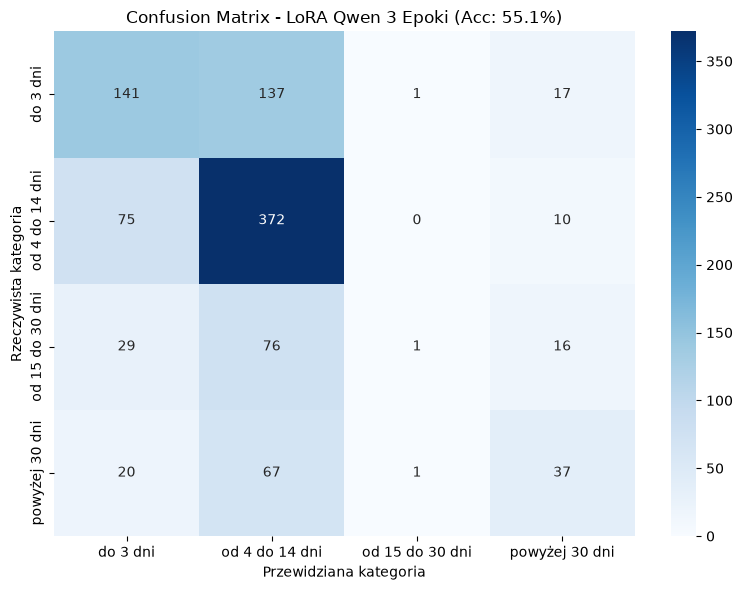

In [9]:
import json
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Definicje klas i przedziałów (dokładnie takie same jak w train.py)
CHOICE_LETTERS = ["A", "B", "C", "D"]
LABELS = [
    "do 3 dni",
    "od 4 do 14 dni",
    "od 15 do 30 dni",
    "powyżej 30 dni"
]
BINS = [-np.inf, 3.0, 14.0, 30.0, np.inf]
QUESTION = "Jak długo pies pozostanie w schronisku?"
URL = "http://localhost:8000/v1/decide"
HEADERS = {"Content-Type": "application/json"}

# 2. Wczytanie danych z pliku CSV
DATA_PATH = "../data/austin/raw/aac_intakes_outcomes.csv"
df = pd.read_csv(DATA_PATH)

# Filtrujemy tylko psy i usuwamy braki w targetcie
if "animal_type" in df.columns:
    df = df[df["animal_type"] == "Dog"].copy()
df = df.dropna(subset=["time_in_shelter_days"]).copy()

# Wyznaczamy etykiety docelowe
df["target_category"] = pd.cut(df["time_in_shelter_days"], bins=BINS, labels=False).astype(int)

# Pobieramy losową próbkę testową (np. 100 lub 200 psów)
test_sample = df.sample(n=1000, random_state=42).reset_index(drop=True)

# 3. Formatowanie opisu psa (identycznie jak podczas treningu)
def row_to_state(row):
    raw_sex = str(row.get("sex_upon_intake", ""))
    if "Male" in raw_sex:
        plec = "Samiec"
    elif "Female" in raw_sex:
        plec = "Samica"
    else:
        plec = "Nieznana"
        
    if "Neutered" in raw_sex or "Spayed" in raw_sex:
        kastracja = "wykastrowany/wysterylizowana"
    elif "Intact" in raw_sex:
        kastracja = "płodny"
    else:
        kastracja = "brak danych"

    rasa = str(row.get("breed", "mieszaniec"))
    kolor = str(row.get("color", "nieznany"))
    stan = str(row.get("intake_condition", "Normal"))
    typ = str(row.get("intake_type", "Nieznany"))
    wiek = row.get("age_upon_intake_(years)", "nieznany")

    return (
        f"Pies trafił do schroniska w stanie: {stan}. "
        f"Typ przyjęcia: {typ}. Wiek: około {wiek} lat. "
        f"Płeć i stan: {plec}, {kastracja}. Rasa: {rasa}. Maść: {kolor}."
    )

# 4. Pętla ewaluacyjna wysyłająca zapytania do server.py
session = requests.Session()
y_true = []
y_pred = []

for idx, row in tqdm(test_sample.iterrows(), total=len(test_sample), desc="Ewaluacja 3-epokowego LoRA"):
    state_desc = row_to_state(row)
    true_label = int(row["target_category"])
    
    payload = {
        "state": state_desc,
        "questions": [{"question": QUESTION, "options": LABELS}]
    }
    
    try:
        res = session.post(URL, json=payload, headers=HEADERS, timeout=30)
        if res.status_code == 200:
            data = res.json()
            if data and "decisions" in data:
                probs = data["decisions"][0]["probabilities"]
                pred_label = int(np.argmax(probs))
                
                y_true.append(true_label)
                y_pred.append(pred_label)
        else:
            print(f"Błąd HTTP {res.status_code} przy rekordzie {idx}")
    except Exception as e:
        print(f"Błąd połączenia przy rekordzie {idx}: {e}")

# 5. Wyniki i raport metryk
print("\n" + "="*50)
print(f"Przetestowano rekordów: {len(y_true)}")
acc = accuracy_score(y_true, y_pred) * 100
print(f"Dokładność (Accuracy): {acc:.2f}%\n")
print(classification_report(y_true, y_pred, target_names=LABELS, zero_division=0))
print("="*50)

# 6. Wizualizacja: Macierz Pomyłek (Confusion Matrix)
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3])
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
            xticklabels=LABELS, yticklabels=LABELS)
plt.title(f"Confusion Matrix - LoRA Qwen 3 Epoki (Acc: {acc:.1f}%)")
plt.xlabel("Przewidziana kategoria")
plt.ylabel("Rzeczywista kategoria")
plt.tight_layout()
plt.show()

In [8]:
X = df_dogs.drop(columns=["time_in_shelter_days", "time_in_shelter","outcome_subtype","outcome_type","sex_upon_outcome","intake_datetime"])
Y = df_dogs["time_in_shelter_days"]
cathegorical_features = ["intake_condition","intake_type","age_upon_intake_age_group","sex","intact","primary_breed_top","age_group"]

train_end = int(len(X) * 0.8)
X_train, X_test = X[:train_end], X[train_end:]
y_train, y_test = Y[:train_end], Y[train_end:]
Y.head()

0    0.588194
1    1.259722
2    1.113889
3    4.970139
4    0.119444
Name: time_in_shelter_days, dtype: float64

In [4]:


model_reg = CatBoostRegressor(
    iterations=600,
    learning_rate=0.03,
    depth=6,
    loss_function='RMSE',
    random_seed=42,
    verbose=100
)

# Trenowanie
model_reg.fit(
    X_train, y_train,
    cat_features=cathegorical_features,
    eval_set=(X_test, y_test),
    early_stopping_rounds=50,
    use_best_model=True
)


0:	learn: 48.5251940	test: 22.7691818	best: 22.7691818 (0)	total: 221ms	remaining: 2m 12s
100:	learn: 47.2293828	test: 21.4200110	best: 21.4200110 (100)	total: 3.97s	remaining: 19.6s
200:	learn: 46.9247458	test: 21.2372983	best: 21.2372983 (200)	total: 7.69s	remaining: 15.3s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 21.22660989
bestIteration = 225

Shrink model to first 226 iterations.


CatBoostRegressor(depth=6, iterations=600, learning_rate=0.03, loss_function='RMSE', random_seed=42, verbose=100)

# MSE


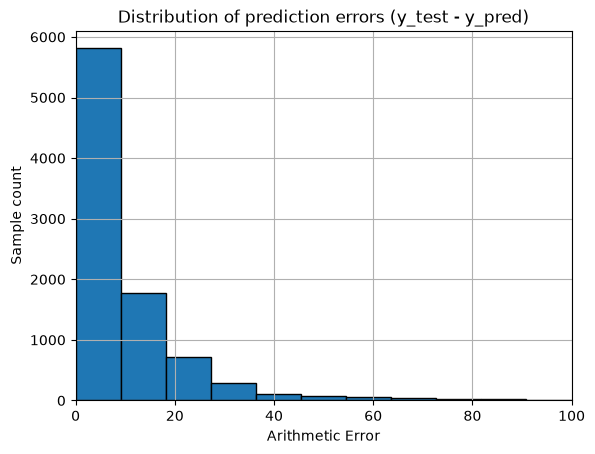

MSE:  450.5690
RMSE: 21.2266 (day unit
MAE:  11.2673
R²:   0.0824


In [5]:

y_pred = model_reg.predict(X_test)

mae_df = pd.DataFrame({"y_test": y_test, "y_pred": y_pred})
mae_df["ArithmeticError"] = np.abs(mae_df["y_test"] - mae_df["y_pred"])

mae_df["ArithmeticError"].hist(bins=40, edgecolor="black")
plt.title("Distribution of prediction errors (y_test - y_pred)")
plt.xlabel("Arithmetic Error")
plt.ylabel("Sample count")
plt.xlim(0,100)
plt.show()

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE:  {mse:.4f}") 
print(f"RMSE: {rmse:.4f} (day unit")
print(f"MAE:  {mae:.4f}")
print(f"R²:   {r2:.4f}")

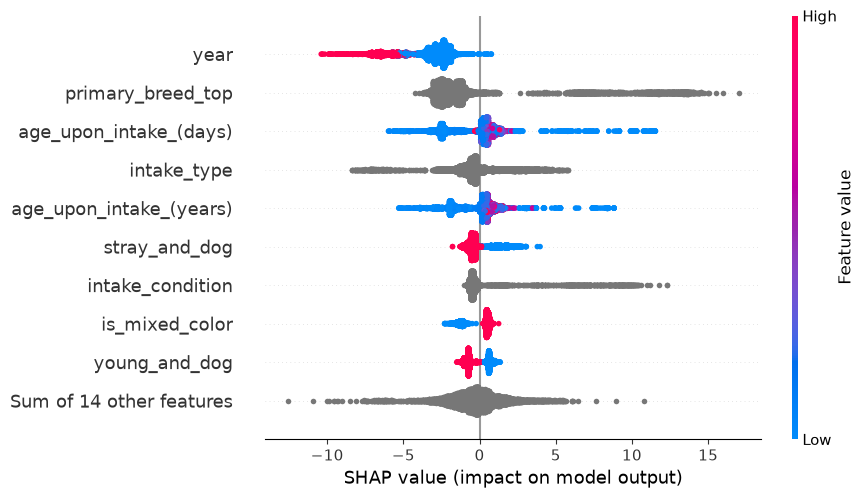

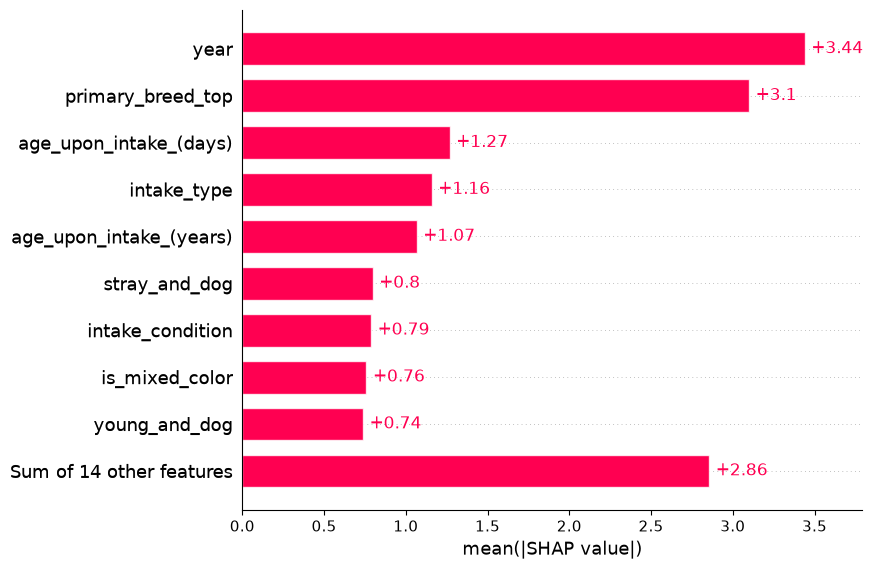

In [6]:



explainer = shap.TreeExplainer(model_reg)


shap_values = explainer(X_test)


shap.plots.beeswarm(shap_values)
shap.plots.bar(shap_values)